In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text
from helpers import get_connection, total_records

In [3]:
engine = get_connection()

In [4]:
total_records(engine, 'users')

Total No. of users: 20,556


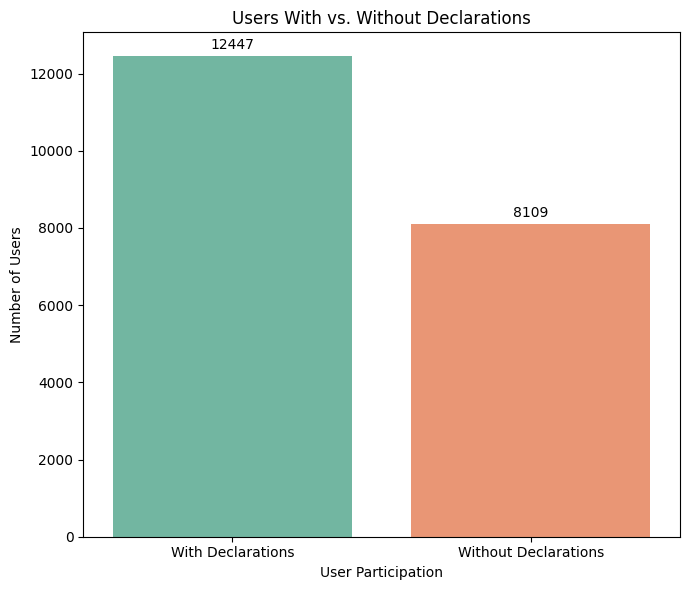

In [5]:
query = """
SELECT
    COUNT(DISTINCT u.id) FILTER (WHERE d.user_id IS NOT NULL) AS users_with_declarations,
    COUNT(DISTINCT u.id) FILTER (WHERE d.user_id IS NULL) AS users_without_declarations
FROM cleaned.users AS u
LEFT JOIN cleaned.declarations AS d
    ON u.id = d.user_id
"""

user_counts = pd.read_sql_query(text(query), engine)

user_declaration = pd.DataFrame({
    'User Status': ['With Declarations', 'Without Declarations'],
    'User Count': [
        user_counts['users_with_declarations'].iloc[0],
        user_counts['users_without_declarations'].iloc[0]
    ]
})

plt.figure(figsize=(7, 6))

ax = sns.barplot(
    data=user_declaration,
    x='User Status',
    y='User Count',
    hue='User Status',
    palette='Set2',
    legend=False
)

# Add labels to every bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

plt.title('Users With vs. Without Declarations')
plt.xlabel('User Participation')
plt.ylabel('Number of Users')

plt.tight_layout()
plt.show()


In [11]:
query = """
SELECT
    d.user_id,
    COUNT(d.user_id) AS declaration_count
FROM cleaned.declarations AS d
GROUP BY d.user_id
ORDER BY declaration_count DESC
"""

user_distribution = pd.read_sql_query(text(query), engine)
user_distribution.head(10)

,user_id,declaration_count
0,4f78bf1c-a388-43b0-9c09-71afd1940428,7489
1,e0754974-eefd-4ac4-a0f1-4d0e774b0d67,6294
2,20544542-8f93-440a-bd6b-4b4a61d7e3de,6119
3,6273f24d-b8ea-430d-a615-6475f117b5ff,5635
4,ee026d7e-1786-482a-aea7-5022ed538831,5385
5,473f59f0-551f-45e3-b4e6-f2b36fe02558,5332
6,ba256eb0-f3bf-4023-b805-35c7614d21d0,5269
7,d02c8848-2588-4a2b-aed4-05a485a34045,5122
8,5bb7a1be-ba07-451b-b80a-6854757f1f98,5121
9,842079b5-5366-4a22-a8b2-2c929616f36c,5108


In [10]:
query = """
SELECT
    t.id AS team_id,
    COUNT(u.id) AS user_count
FROM cleaned.teams AS t
LEFT JOIN cleaned.users AS u
    ON t.id = u.team_id
GROUP BY t.id
ORDER BY user_count DESC
"""

team_distribution = pd.read_sql_query(text(query), engine)
team_distribution.head(10)

,team_id,user_count
0,cad594d3-e120-4e64-88ba-02d755643bbc,1621
1,492236e8-866f-40b6-9450-55fe3dc37631,420
2,a1e7b8bb-34f0-4e86-89cd-f941f179e337,222
3,1761ef97-c3c9-41a5-ae0f-156f63138c50,221
4,99726867-5377-40e2-a614-e1aead83244f,208
5,dd679f42-f0e9-4b66-8a36-c65b887906b7,193
6,7825383d-a2ce-48a2-bfeb-ba9966d2a829,185
7,a389ed27-7e2e-412b-97ae-2ff39c5b5808,167
8,f6c5913f-3648-494a-85e3-ae13ba860b9a,154
9,db97c470-86c1-4238-830c-de416d9553dc,135


In [ ]:
total_records(engine,'teams')

Total No. of teams: 2,838


In [ ]:
total_records(engine, 'projects')

Total No. of projects: 71,792


In [ ]:
total_records(engine, 'tasks')

Total No. of tasks: 717,470


In [ ]:
total_records(engine, 'declarations')

Total No. of declarations: 4,446,669
